# SVD Background Detection

## Libraries import

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Video import
Load `Video_008.avi` from the [Background Models Challenge](https://backgroundmodelschallenge.eu/) (`bmc_real.zip`). Use all frames at their original resolution and convert them to grayscale for the decomposition.

In [2]:
# Support running from either the src directory or the project root
video_path = Path('Video_008.avi')
if not video_path.is_file():
    video_path = Path('src') / 'Video_008.avi'
if not video_path.is_file():
    raise FileNotFoundError('Place Video_008.avi in the src directory.')

capture = cv2.VideoCapture(str(video_path))
if not capture.isOpened():
    capture.release()
    raise RuntimeError(f'Cannot open {video_path}')

frames = []
try:
    fps = capture.get(cv2.CAP_PROP_FPS)
    expected_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    while True:
        success, frame = capture.read()
        if not success:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
finally:
    capture.release()

if not frames:
    raise RuntimeError('The video contains no readable frames.')
if expected_frames > 0 and len(frames) != expected_frames:
    print(f'Note: AVI metadata reports {expected_frames} frames; {len(frames)} frames were decoded.')

frames = np.stack(frames)
n_frames, height, width = frames.shape
print(f'Frames: {n_frames} | Frame size: {width} x {height} | FPS: {fps:g}')
if fps > 0:
    print(f'Duration: {n_frames / fps:.1f} s')

Note: AVI metadata reports 793 frames; 792 frames were decoded.
Frames: 792 | Frame size: 320 x 240 | FPS: 10
Duration: 79.2 s


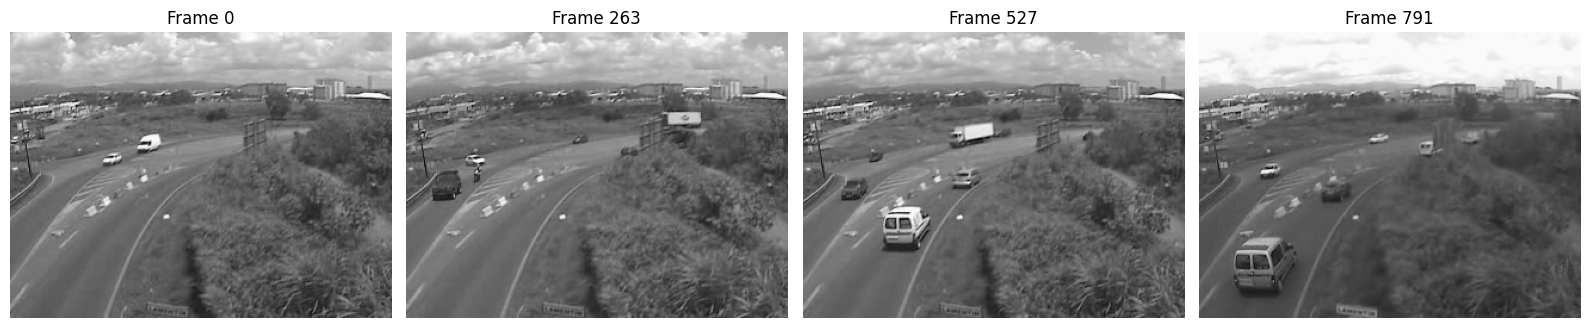

In [3]:
frame_idx = np.linspace(0, n_frames - 1, 4, dtype=int)
fig, ax = plt.subplots(ncols=4, nrows=1, figsize=(16, 4))
for axis, idx in zip(ax, frame_idx):
    axis.imshow(frames[idx], cmap='gray', vmin=0, vmax=255)
    axis.set_title(f'Frame {idx}')
    axis.axis('off')
plt.tight_layout()
plt.show()

## Video as a matrix
Each column of $X$ is one flattened grayscale frame, so $X$ has shape $(H W, T)$, where $T$ is the number of frames. Pixel values are scaled to $[0, 1]$. The matrix is **not centered**: the persistent background should remain in the leading singular component.

In [4]:
X = frames.reshape(n_frames, -1).T.astype(np.float32) / 255
first_frame = X[:, 0].reshape(height, width)
print(f'Matrix shape: {X.shape} (pixels, frames)')
print(f'Matrix memory: {X.nbytes / 1024**2:.1f} MiB')

Matrix shape: (76800, 792) (pixels, frames)
Matrix memory: 232.0 MiB


## SVD decomposition
Compute the reduced SVD $X = U\Sigma V^T$. Columns of $U$ describe spatial patterns, and rows of $V^T$ describe their changes over time. A stationary scene is shared across frames and should dominate the first component.

In [5]:
t0 = time.time()
U, s, Vt = np.linalg.svd(X, full_matrices=False)
svd_time = time.time() - t0

energy = s.astype(np.float64) ** 2
cumulative_energy = np.cumsum(energy) / energy.sum()
print(f'U: {U.shape} | s: {s.shape} | Vt: {Vt.shape}')
print(f'SVD time: {svd_time:.2f} s')
print(f'Rank-1 retained energy: {cumulative_energy[0]:.2%}')

U: (76800, 792) | s: (792,) | Vt: (792, 792)
SVD time: 17.83 s
Rank-1 retained energy: 98.09%


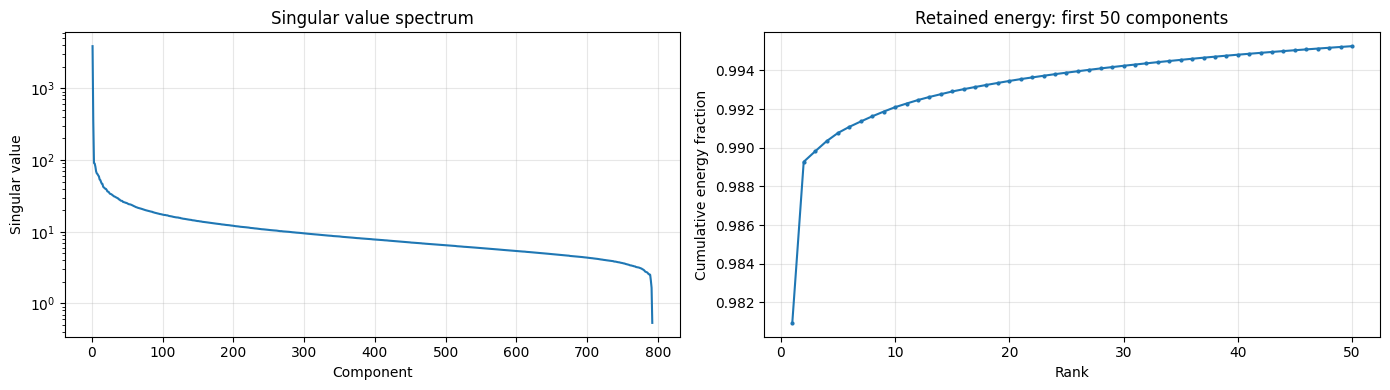

In [6]:
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(14, 4))
components = np.arange(1, len(s) + 1)
ax[0].semilogy(components, s)
ax[0].set_title('Singular value spectrum')
ax[0].set_xlabel('Component')
ax[0].set_ylabel('Singular value')
ax[1].plot(components[:50], cumulative_energy[:50], marker='.', markersize=4)
ax[1].set_title('Retained energy: first 50 components')
ax[1].set_xlabel('Rank')
ax[1].set_ylabel('Cumulative energy fraction')
for axis in ax:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## First frame reconstruction
The rank-$k$ approximation is $X_k = U_{:,1:k}\Sigma_{1:k,1:k}V^T_{1:k,:}$. Only its first column is needed to reconstruct the first frame. Compare several ranks using the same grayscale range. RMSE measures similarity to the original frame (including foreground), not background quality.

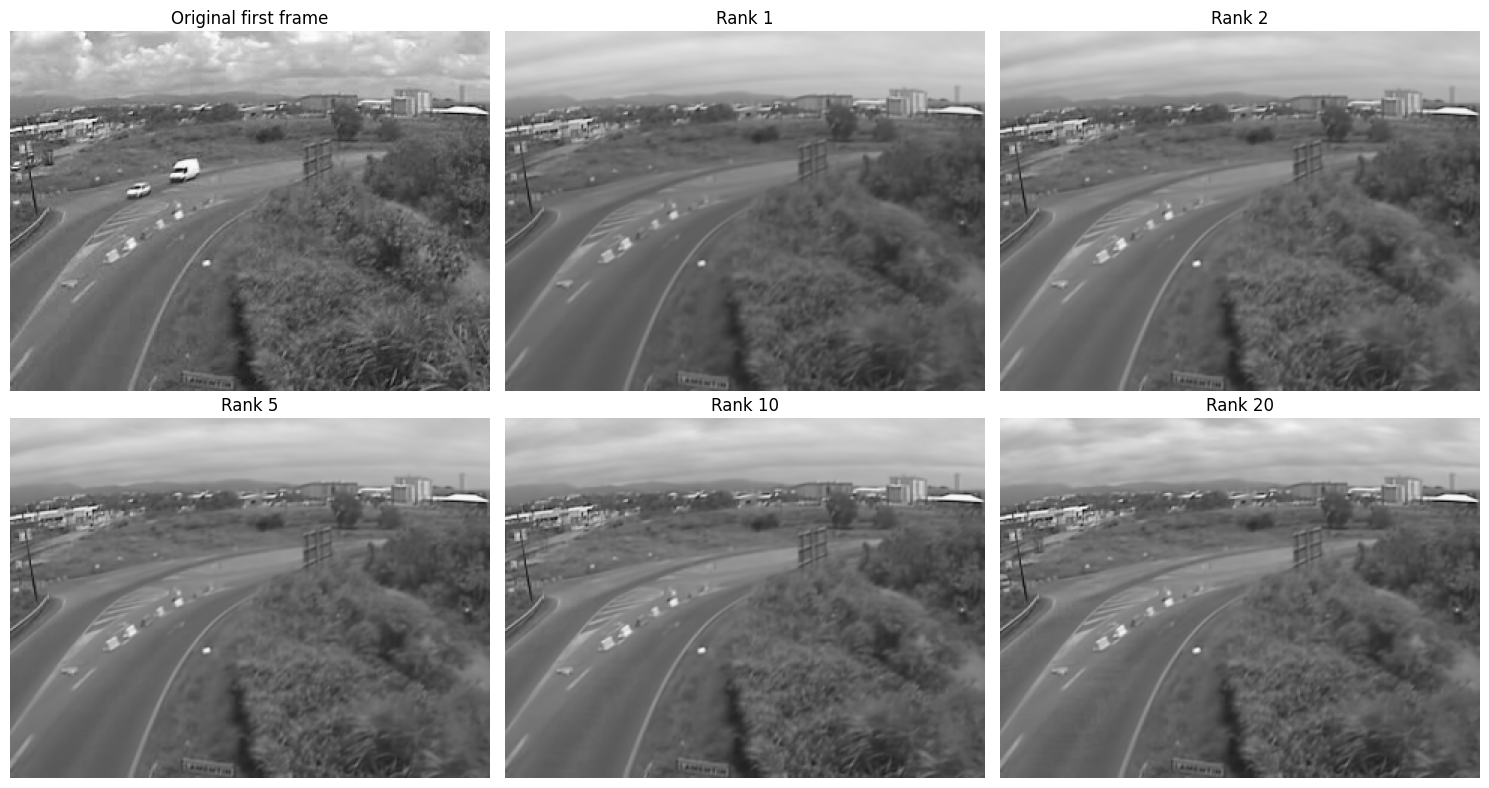

,Rank,First-frame RMSE,Retained video energy
0,1,0.0530,0.9809
1,2,0.0436,0.9893
2,5,0.0427,0.9908
3,10,0.0416,0.9921
4,20,0.0396,0.9935


In [7]:
ranks = [1, 2, 5, 10, 20]
reconstructions = {}
results = []

for rank in ranks:
    recovered = (U[:, :rank] @ (s[:rank] * Vt[:rank, 0])).reshape(height, width)
    reconstructions[rank] = recovered
    # Calculate errors before clipping the image for display
    rmse = np.sqrt(np.mean((first_frame - recovered) ** 2))
    results.append([rank, rmse, cumulative_energy[rank - 1]])

fig, ax = plt.subplots(ncols=3, nrows=2, figsize=(15, 8))
ax = ax.ravel()
ax[0].imshow(first_frame, cmap='gray', vmin=0, vmax=1)
ax[0].set_title('Original first frame')
for axis, (rank, recovered) in zip(ax[1:], reconstructions.items()):
    axis.imshow(np.clip(recovered, 0, 1), cmap='gray', vmin=0, vmax=1)
    axis.set_title(f'Rank {rank}')
for axis in ax:
    axis.axis('off')
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results, columns=['Rank', 'First-frame RMSE', 'Retained video energy'])
display(results_df.round(4))

## Background and residual

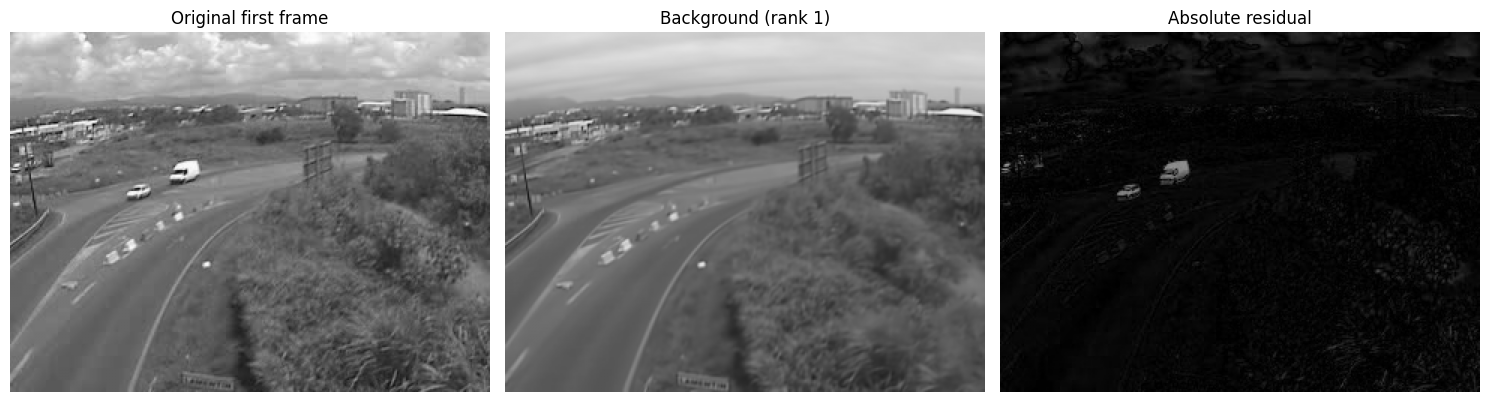

In [8]:
background_rank = 1
background = reconstructions[background_rank]
residual = np.abs(first_frame - background)

fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(15, 4))
for axis, image, title in zip(ax, [first_frame, np.clip(background, 0, 1), residual],
                             ['Original first frame', 'Background (rank 1)', 'Absolute residual']):
    axis.imshow(image, cmap='gray', vmin=0, vmax=1)
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## Conclusion
Use **rank 1** to estimate the background of this video. It retains **98.09%** of the video matrix energy and suppresses the two vehicles visible in the first frame, while preserving the road, buildings and vegetation. Clouds and moving vegetation are smoothed. Higher ranks restore more scene variation, particularly cloud detail; foreground traces can also enter the reconstruction. A lower reconstruction error at higher ranks does not imply a better background estimate.

The rank-1 result is an approximation: moving objects can leave faint traces, and changes in illumination or background motion can appear in the residual. The absolute residual is not a binary foreground mask. Without a ground-truth background, rank 1 is a visually justified simple choice, not a proven optimum.